# Data Preprocessing and Exploratory Data Analysis

## Can Historical Earnings Patterns Predict Future Earnings Surprises?

This notebook explores the Sov.ai Earnings Surprise dataset to gain a better understanding of the data and identify any issues or patterns worth further investigating.

The primary research objective is to determine whether information from a company's four preceding recorded earnings events can predict whether its next reported earnings per share exceeds analyst expectations.

### Objectives

- Examine the dataset's structure and coverage.
- Investigate missing values and repeated source records.
- Analyze earnings-event and target distributions.
- Explore historical features and their relationships.
- Document preprocessing decisions and data limitations.

**Dataset:** Sov.ai Earnings Surprise

**Methodology:** The source contains repeated observations associated with earnings events. These records are audited and reconstructed into candidate events before creating historical prediction examples.


In [1]:

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display

from earnings_surprise.data.download import (
    DATASET_FILENAME,
    EXPECTED_SHA256,
    calculate_sha256,
    download_dataset,
)

from earnings_surprise.data.inspect import summarize_dataset
from earnings_surprise.data.audit_snapshots import (
    summarize_snapshot_repetition,
)


def find_project_root() -> Path:
    """locates the project root from the current directory"""
    current_directory = Path.cwd().resolve()

    for directory in [current_directory, *current_directory.parents]:
        if (directory / "pyproject.toml").is_file():
            return directory

    raise FileNotFoundError("Project root could not be located")


PROJECT_ROOT = find_project_root()

DATASET_PATH = (
    PROJECT_ROOT / "data" / "raw" / DATASET_FILENAME
)

if not DATASET_PATH.is_file():
    DATASET_PATH = download_dataset(
        PROJECT_ROOT / "data" / "raw"
    )

if calculate_sha256(DATASET_PATH) != EXPECTED_SHA256:
    raise ValueError("Dataset checksum verification failed")

raw_data = pd.read_parquet(DATASET_PATH)

print("Dataset loaded successfully")
print(f"Rows: {len(raw_data):,}")
print(f"Columns: {len(raw_data.columns)}")

Dataset loaded successfully
Rows: 1,657,661
Columns: 7


/Users/xrch/earnings-surprise-prediction/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("Dataset Preview")
display(raw_data.head())

print("\nDataset Information")
raw_data.info()

print("\nSummary Statistics")
display(raw_data.describe(include="all"))

print("\nColumn Types")
display(
    raw_data.dtypes.to_frame(name="Data Type")
)

Dataset Preview


,ticker,date,surprise_probability,eps_surprise,actual_earning_result,estimated_earning,date_pub
0,A,2016-12-30,0.152089,0.04,0.53,0.49,2017-02-14
1,A,2017-01-06,0.216606,0.04,0.53,0.49,2017-02-14
2,A,2017-01-13,0.191768,0.04,0.53,0.49,2017-02-14
3,A,2017-01-20,0.178075,0.04,0.53,0.49,2017-02-14
4,A,2017-01-27,0.180252,0.04,0.53,0.49,2017-02-14



Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1657661 entries, 0 to 1657660
Data columns (total 7 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   ticker                 1657661 non-null  str           
 1   date                   1657661 non-null  datetime64[ns]
 2   surprise_probability   1657661 non-null  float64       
 3   eps_surprise           1623370 non-null  float64       
 4   actual_earning_result  1623370 non-null  float64       
 5   estimated_earning      1657189 non-null  float64       
 6   date_pub               1623383 non-null  datetime64[ms]
dtypes: datetime64[ms](1), datetime64[ns](1), float64(4), str(1)
memory usage: 94.2 MB

Summary Statistics


,ticker,date,surprise_probability,eps_surprise,actual_earning_result,estimated_earning,date_pub
count,1657661,1657661,1.657661e+06,1.623370e+06,1.623370e+06,1.657189e+06,1623383
unique,5739,NaN,NaN,NaN,NaN,NaN,NaN
top,A,NaN,NaN,NaN,NaN,NaN,NaN
freq,383,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2020-10-19 11:01:53.297229312,1.151834e-04,-7.339225e+01,-2.915987e+02,-5.995336e+04,2021-02-08 07:32:28.639000
min,NaN,2016-12-30 00:00:00,-5.115261e-01,-4.702971e+06,-5.997002e+06,-2.250000e+09,2016-12-24 00:00:00
25%,NaN,2019-01-11 00:00:00,-2.312481e-01,-4.000000e-02,-1.600000e-01,-1.300000e-01,2019-05-02 00:00:00
50%,NaN,2020-11-27 00:00:00,7.497184e-04,2.000000e-02,2.000000e-01,1.800000e-01,2021-04-28 00:00:00
75%,NaN,2022-08-05 00:00:00,2.304762e-01,1.000000e-01,7.100000e-01,6.700000e-01,2022-11-14 00:00:00
max,NaN,2024-04-26 00:00:00,5.116805e-01,1.862432e+06,1.852194e+06,3.600000e+03,2024-10-30 00:00:00



Column Types


,Data Type
ticker,str
date,datetime64[ns]
surprise_probability,float64
eps_surprise,float64
actual_earning_result,float64
estimated_earning,float64
date_pub,datetime64[ms]


In [3]:
inspection = summarize_dataset(raw_data)
repetition = summarize_snapshot_repetition(raw_data)

missing_values = pd.DataFrame({
    "Missing Values": raw_data.isna().sum(),
    "Missing (%)": (
        raw_data.isna().mean() * 100
    ).round(2),
})

print("Missing Values")
display(missing_values)

print(f"Exact duplicate rows: {repetition['exact_duplicate_rows']:,}")

print(
    "Candidate earnings events: "
    f"{repetition['candidate_key_count']:,}"
)

print(
    "Candidate events with repeated records: "
    f"{repetition['keys_with_multiple_rows']:,}"
)

print(
    "Records without usable candidate keys: "
    f"{repetition['rows_without_candidate_key']:,}"
)

Missing Values


,Missing Values,Missing (%)
ticker,0,0.00
date,0,0.00
surprise_probability,0,0.00
eps_surprise,34291,2.07
actual_earning_result,34291,2.07
estimated_earning,472,0.03
date_pub,34278,2.07


Exact duplicate rows: 0
Candidate earnings events: 111,989
Candidate events with repeated records: 111,588
Records without usable candidate keys: 34,278


## Data Quality Analysis

### Missing Values

This section involves examining missing values in the original source
records, with the aim being identifying incomplete observations and
potential challenges for subsequent preprocessing.

Missingness is reported at the source-record level. Since the
dataset contains repeated records for earnings events these
figures do not necessarily represent missingness in the
reconstructed event-level dataset.

Missing Values by Column


,missing_count,missing_percent
eps_surprise,34291,2.068638
actual_earning_result,34291,2.068638
date_pub,34278,2.067853
estimated_earning,472,0.028474
ticker,0,0.000000
date,0,0.000000
surprise_probability,0,0.000000


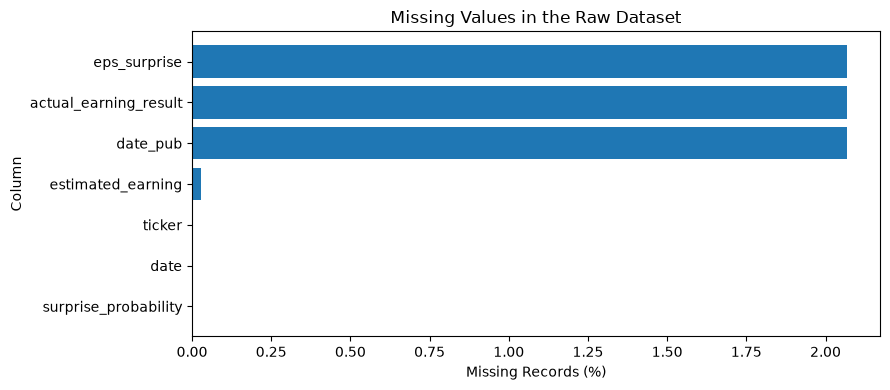

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": raw_data.isna().sum(),
    "missing_percent": raw_data.isna().mean() * 100,
})

missing_summary = missing_summary.sort_values(
    "missing_count", ascending=False
)

print("Missing Values by Column")
display(missing_summary)

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(
    missing_summary.index,
    missing_summary["missing_percent"],
)

ax.invert_yaxis()
ax.set_xlabel("Missing Records (%)")
ax.set_ylabel("Column")
ax.set_title("Missing Values in the Raw Dataset")

plt.tight_layout()
plt.show()

### Duplicate and Repeated Records

The source dataset contains repeated observations associated
with the same ticker and earnings publication date.

I distinguish exact duplicate rows from repeated candidate
earnings events. Multiple records with the same candidate key
may contain different source dates while referring to the
same recorded earnings outcome.

In [5]:
repetition_summary = summarize_snapshot_repetition(raw_data)

quality_metrics = {
    "Total source records": repetition_summary["total_rows"],
    "Exact duplicate rows": repetition_summary["exact_duplicate_rows"],
    "Candidate earnings events": repetition_summary["candidate_key_count"],
    "Events with repeated records": repetition_summary["keys_with_multiple_rows"],
    "Extra rows from repetition": repetition_summary["extra_rows_from_repetition"],
    "Rows without candidate keys": repetition_summary["rows_without_candidate_key"],
}

quality_table = pd.DataFrame(
    quality_metrics.items(),
    columns=["Metric", "Count"],
)

display(quality_table)

,Metric,Count
0,Total source records,1657661
1,Exact duplicate rows,0
2,Candidate earnings events,111989
3,Events with repeated records,111588
4,Extra rows from repetition,1511394
5,Rows without candidate keys,34278



### Data Quality Findings

The source dataset contains 1,657,661 records associated with
111,989 candidate earnings events.

Although no exact duplicate rows were identified, 111,588
candidate earnings events are associated with multiple source
records. These repetitions occur because the source contains
multiple observations associated with the same event.

The initial audit also found that many earlier-dated source
records already contain the eventual earnings result. Therefore,
the source `date` field cannot be interpreted as proof that
the financial values were available on that date.

To address these issues, I reconstruct candidate
earnings events using the provisional `(ticker, date_pub)` key.

Financial values are consolidated only after consistency
checks. Incomplete events and source-row provenance are
preserved for subsequent analysis.

## Reconstructed Earnings Events

The repeated source observations are consolidated into
candidate earnings events before constructing historical
prediction examples.

This avoids treating multiple records of the same earnings
event as independent observations

In [6]:
from earnings_surprise.data.events import (
    build_candidate_event_ledger,
)

from earnings_surprise.data.samples import (
    build_prediction_windows,
)


event_data, event_summary = build_candidate_event_ledger(raw_data)

prediction_data, prediction_summary = build_prediction_windows(
    event_data
)

dataset_stages = pd.DataFrame({
    "Dataset Stage": [
        "Original source records",
        "Reconstructed candidate events",
        "Eligible prediction samples",
    ],
    "Records": [
        len(raw_data),
        len(event_data),
        len(prediction_data),
    ],
})

display(dataset_stages)

,Dataset Stage,Records
0,Original source records,1657661
1,Reconstructed candidate events,111989
2,Eligible prediction samples,90349


,Outcome,Count
0,Beat,50859
1,Meet or Miss,31494


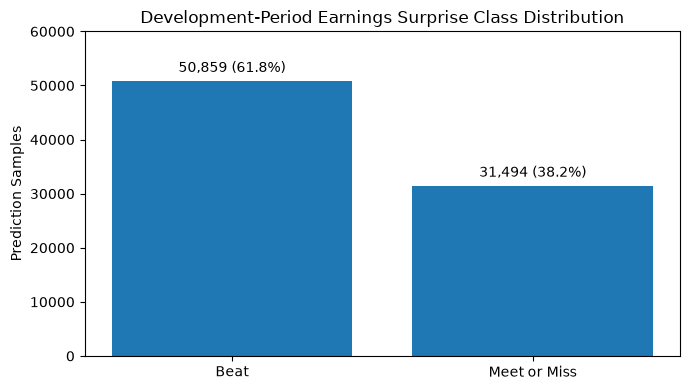

In [7]:

# reserve 2024 data for later evaluation
EDA_CUTOFF = pd.Timestamp("2024-01-01")

development_mask = (
    prediction_data["target_date_pub"] < EDA_CUTOFF
)

development_targets = prediction_data.loc[
    development_mask, "target_beat"
]

target_counts = pd.DataFrame({
    "Outcome": ["Beat", "Meet or Miss"],
    "Count": [
        int(development_targets.eq(1).sum()),
        int(development_targets.eq(0).sum()),
    ],
})

display(target_counts)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    target_counts["Outcome"],
    target_counts["Count"],
)

labels = [
    f"{count:,} ({count / len(development_targets):.1%})"
    for count in target_counts["Count"]
]

ax.bar_label(bars, labels=labels, padding=4)

ax.set_ylabel("Prediction Samples")
ax.set_title("Development-Period Earnings Surprise Class Distribution")
ax.margins(y=0.18)

plt.tight_layout()
plt.show()

## Historical Feature Analysis

The prediction dataset contains 25 candidate features derived
from each company's four preceding recorded earnings events.

These features include historical actual and estimated EPS,
earnings surprises, previous beat indicators, summary statistics
and calendar variables.

The following analysis examines the distributions and
relationships among these predictors.

This analysis will initially focus on prediction targets dated before January 1, 2024.

The final chronological evaluation boundaries will be
confirmed separately before model development.

In [8]:
from earnings_surprise.features import (
    FEATURE_COLUMNS,
    build_historical_features,
)

feature_data = build_historical_features(
    prediction_data,
    event_data,
)

assert len(feature_data) == len(prediction_data)
assert feature_data.columns.tolist() == FEATURE_COLUMNS
assert feature_data.index.equals(prediction_data.index)

# provisional development-period boundary
EDA_CUTOFF = pd.Timestamp("2024-01-01")

development_mask = (
    prediction_data["target_date_pub"] < EDA_CUTOFF
)

development_features = feature_data.loc[
    development_mask
].copy()

print(f"All prediction samples: {len(feature_data):,}")
print(f"Development samples: {len(development_features):,}")
print(f"Reserved 2024 samples: {(~development_mask).sum():,}")

print("\nHistorical Feature Preview")
display(development_features.head())

print("\nFeature Data Types")
display(
    development_features.dtypes.to_frame(
        name="Data Type"
    )
)

print("\nFeature Summary Statistics")
display(
    development_features.describe(include="all").T
)

All prediction samples: 90,349
Development samples: 82,353
Reserved 2024 samples: 7,996

Historical Feature Preview


,actual_eps_lag1,actual_eps_lag2,actual_eps_lag3,actual_eps_lag4,estimate_eps_lag1,estimate_eps_lag2,estimate_eps_lag3,estimate_eps_lag4,surprise_eps_lag1,surprise_eps_lag2,...,beat_lag4,beat_rate4,surprise_mean4,surprise_std4,eps_change1_2,eps_trend4,surprise_trend4,beat_streak4,previous_report_month,previous_report_quarter
0,0.67,0.59,0.58,0.53,0.62,0.52,0.48,0.49,0.05,0.07,...,1,1.0,0.0650,0.022913,0.08,0.043,0.000,4,11,4
1,0.66,0.67,0.59,0.58,0.58,0.62,0.52,0.48,0.08,0.05,...,1,1.0,0.0750,0.018028,-0.01,0.032,-0.008,4,2,1
2,0.65,0.66,0.67,0.59,0.64,0.58,0.62,0.52,0.01,0.08,...,1,1.0,0.0525,0.026810,-0.01,0.017,-0.015,4,5,2
3,0.67,0.65,0.66,0.67,0.63,0.64,0.58,0.62,0.04,0.01,...,1,1.0,0.0450,0.025000,0.02,-0.001,-0.010,4,8,3
4,0.81,0.67,0.65,0.66,0.73,0.63,0.64,0.58,0.08,0.04,...,1,1.0,0.0525,0.029475,0.14,0.047,0.003,4,11,4



Feature Data Types


,Data Type
actual_eps_lag1,float64
actual_eps_lag2,float64
actual_eps_lag3,float64
actual_eps_lag4,float64
estimate_eps_lag1,float64
estimate_eps_lag2,float64
estimate_eps_lag3,float64
estimate_eps_lag4,float64
surprise_eps_lag1,float64
surprise_eps_lag2,float64



Feature Summary Statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
actual_eps_lag1,82353.0,NaN,NaN,NaN,-85.149421,16576.812597,-4702971.0,-0.08,0.3,0.84,49714.27
actual_eps_lag2,82353.0,NaN,NaN,NaN,-52.823768,12648.96834,-2998501.0,-0.08,0.3,0.82,1852194.0
actual_eps_lag3,82353.0,NaN,NaN,NaN,-124.501387,17660.450636,-2998501.0,-0.08,0.29,0.8,1852194.0
actual_eps_lag4,82353.0,NaN,NaN,NaN,-256.417691,30764.676966,-5997002.0,-0.08,0.29,0.78,1852194.0
estimate_eps_lag1,82353.0,NaN,NaN,NaN,-34.584231,3775.416442,-731619.0,-0.08,0.27,0.76,1425.31
estimate_eps_lag2,82353.0,NaN,NaN,NaN,-83.874778,11441.262349,-2998501.0,-0.08,0.27,0.742,1718.75
estimate_eps_lag3,82353.0,NaN,NaN,NaN,-173.122248,19168.074163,-3134482.0,-0.08,0.26,0.73,1718.75
estimate_eps_lag4,82353.0,NaN,NaN,NaN,-221.574139,21975.80211,-3134482.0,-0.08,0.26,0.71,1718.75
surprise_eps_lag1,82353.0,NaN,NaN,NaN,-50.56519,16678.150275,-4702971.13,-0.02187,0.02,0.11,712318.5
surprise_eps_lag2,82353.0,NaN,NaN,NaN,31.05101,7301.75323,-194040.0,-0.02427,0.02,0.11,1862431.5


### Numerical Feature Distributions

I examine representative features describing historical EPS,
earnings surprises and variation across prior earnings events.

Financial observations may contain extreme values that make
ordinary histograms difficult to interpret.

For visualization only, each histogram displays values
between the 1st and 99th percentiles. The complete
observations remain unchanged in the underlying dataset.

This visualization choice does not remove outliers from
subsequent analysis or model training.

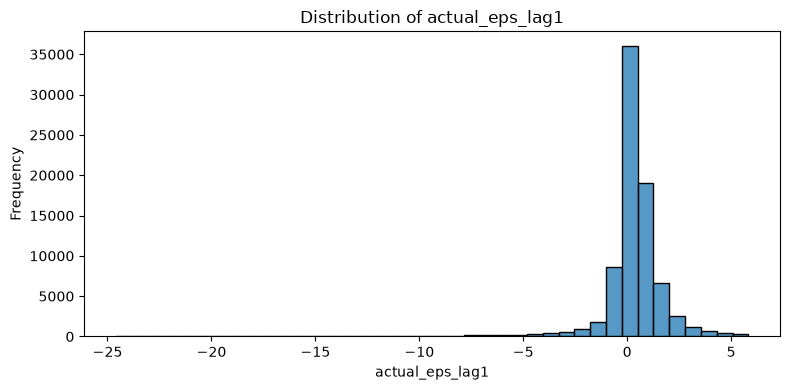

actual_eps_lag1: displaying 80,705 of 82,353 observations


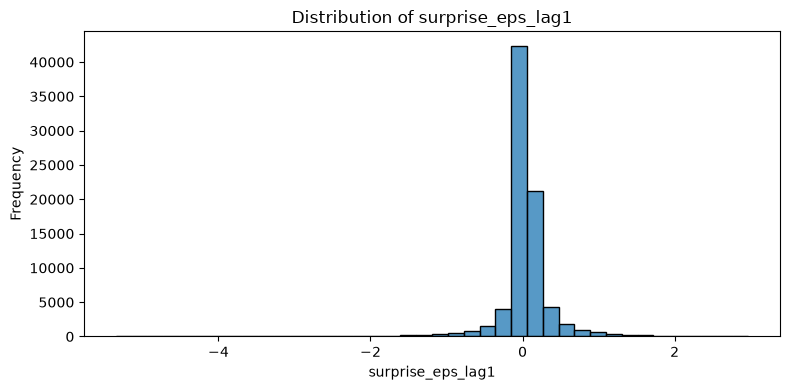

surprise_eps_lag1: displaying 80,705 of 82,353 observations


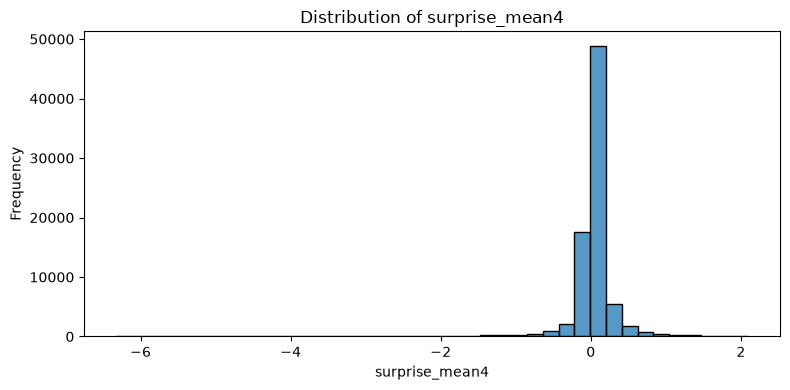

surprise_mean4: displaying 80,705 of 82,353 observations


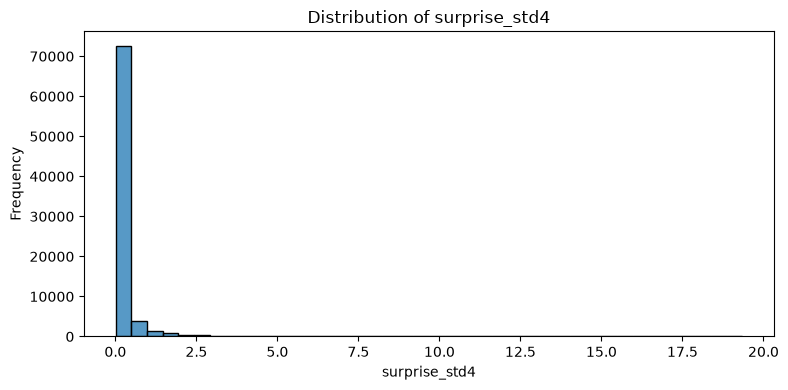

surprise_std4: displaying 80,830 of 82,353 observations


In [9]:

distribution_features = [
    "actual_eps_lag1",
    "surprise_eps_lag1",
    "surprise_mean4",
    "surprise_std4",
]

for column in distribution_features:
    values = development_features[column].astype(float).dropna()

    lower_bound = values.quantile(0.01)
    upper_bound = values.quantile(0.99)

    displayed_values = values[
        values.between(lower_bound, upper_bound)
    ]

    fig, ax = plt.subplots(figsize=(8, 4))

    sns.histplot(
        displayed_values,
        bins=40,
        ax=ax,
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    print(
        f"{column}: displaying {len(displayed_values):,} "
        f"of {len(values):,} observations"
    )


### Correlation Analysis

A Pearson correlation matrix is used to investigate linear
relationships among selected numerical historical features.

Some features are mathematically related. For example,
earnings surprise is calculated from actual and estimated EPS,
while beat rate summarizes historical beat indicators.

Strong correlations may therefore reflect the feature
construction process.

The analysis will help identify redundant predictors and
inform later preprocessing and feature-selection experiments.

Categorical calendar features are excluded from this
numerical correlation matrix.

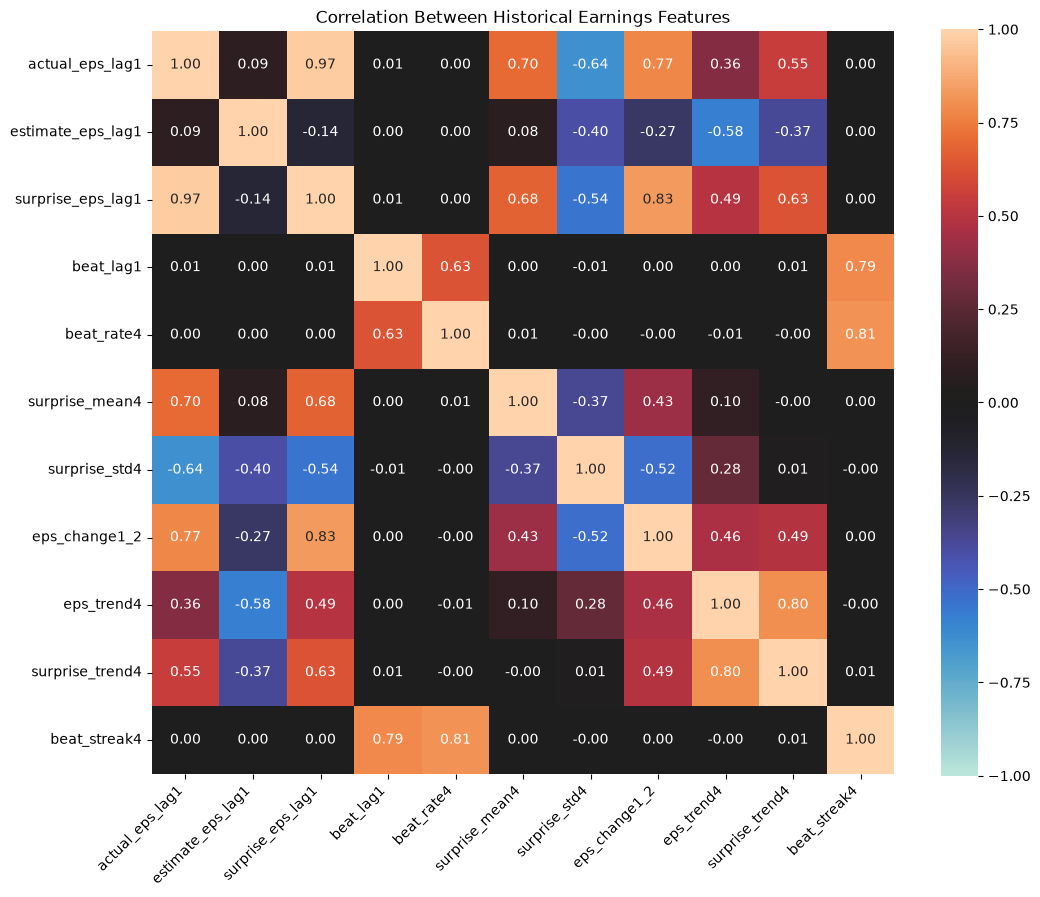

In [10]:
correlation_features = [
    "actual_eps_lag1",
    "estimate_eps_lag1",
    "surprise_eps_lag1",
    "beat_lag1",
    "beat_rate4",
    "surprise_mean4",
    "surprise_std4",
    "eps_change1_2",
    "eps_trend4",
    "surprise_trend4",
    "beat_streak4",
]

correlation_data = development_features[
    correlation_features
].astype(float)

correlation_matrix = correlation_data.corr()

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)

ax.set_title("Correlation Between Historical Earnings Features")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Outlier Analysis

The numerical feature distributions indicate the presence of extreme
earnings observations.

We use the interquartile range (IQR) method to identify observations
outside the typical range of each selected feature.

These flags are exploratory and do not establish that the values are
incorrect. Observations are not removed from the dataset at this stage.

For readability, box plots display observations between the 1st and
99th percentiles. The IQR calculations use all available development
observations.

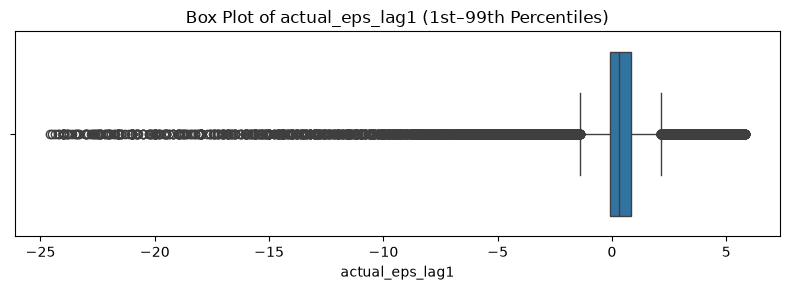

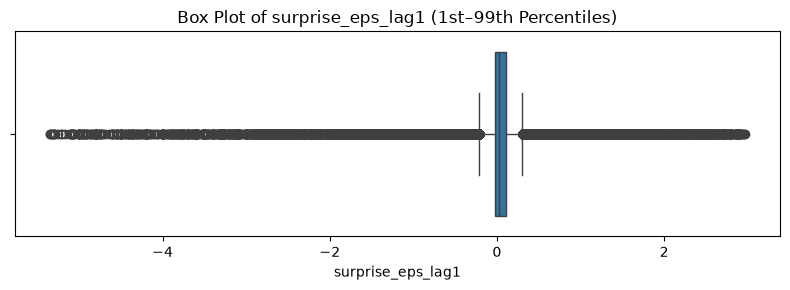

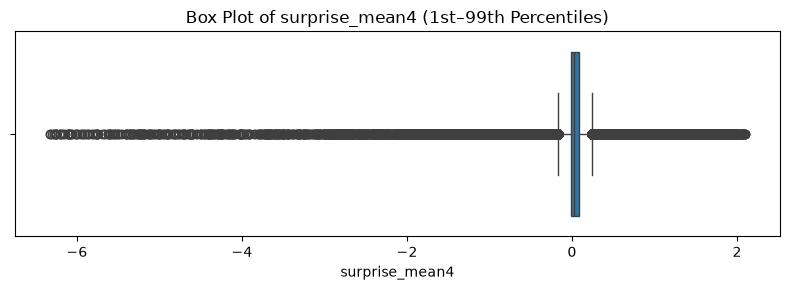

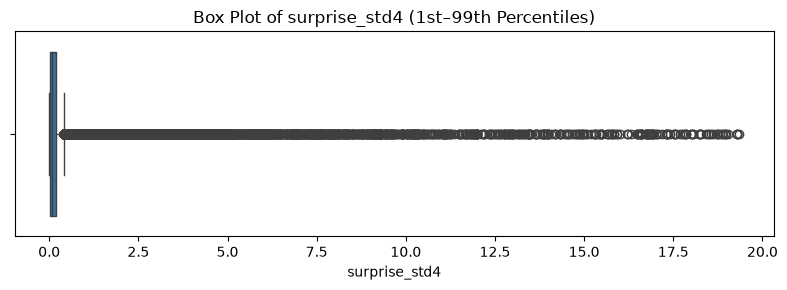

IQR Outlier Summary


,Feature,Lower Bound,Upper Bound,Flagged Records,Flagged (%)
0,actual_eps_lag1,-1.460000,2.220000,9911,12.03
1,surprise_eps_lag1,-0.219675,0.307805,15644,19.00
2,surprise_mean4,-0.176250,0.253750,14674,17.82
3,surprise_std4,-0.206314,0.431034,10089,12.25


In [11]:
IQR_MULTIPLIER = 1.5
LOWER_DISPLAY_QUANTILE = 0.01
UPPER_DISPLAY_QUANTILE = 0.99

outlier_features = [
    "actual_eps_lag1",
    "surprise_eps_lag1",
    "surprise_mean4",
    "surprise_std4",
]

outlier_results = []

for column in outlier_features:
    values = development_features[column].astype(float).dropna()

    first_quartile = values.quantile(0.25)
    third_quartile = values.quantile(0.75)

    iqr = third_quartile - first_quartile

    lower_bound = first_quartile - IQR_MULTIPLIER * iqr
    upper_bound = third_quartile + IQR_MULTIPLIER * iqr

    is_outlier = (values < lower_bound) | (values > upper_bound)

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Flagged Records": int(is_outlier.sum()),
        "Flagged (%)": round(is_outlier.mean() * 100, 2),
    })

    # restricts only the plotted range for readability
    display_lower = values.quantile(LOWER_DISPLAY_QUANTILE)
    display_upper = values.quantile(UPPER_DISPLAY_QUANTILE)

    displayed_values = values[
        values.between(display_lower, display_upper)
    ]

    fig, ax = plt.subplots(figsize=(8, 3))

    sns.boxplot(x=displayed_values, ax=ax)

    ax.set_title(f"Box Plot of {column} (1st–99th Percentiles)")
    ax.set_xlabel(column)

    plt.tight_layout()
    plt.show()

outlier_summary = pd.DataFrame(outlier_results)

print("IQR Outlier Summary")
display(outlier_summary)

### Outlier Analysis Findings

The IQR analysis identified substantial numbers of observations
outside the conventional 1.5 × IQR boundaries.

The proportion of flagged observations ranged from approximately
12% to 19% across the four selected features. The highest
proportion occurred in the latest historical EPS surprise.

The numerical summaries also show considerable differences
between some means and medians, indicating sensitivity to
extreme observations.

These findings suggest that ordinary mean-based scaling and
Pearson correlations may be strongly influenced by unusual
financial values.

IQR flags do not necessarily represent erroneous observations.
All flagged records are retained at this stage.

Any subsequent outlier treatment will be investigated using
development data, with validation observations preserved for
fair comparisons.

## Data Preprocessing

### Chronological Development Split

Preprocessing transformations must be fitted using training
data only to avoid incorporating information from validation
or test observations.

For this preprocessing demonstration, observations before
2023 form the training population, while observations from
2023 form the validation population.

The 2024 prediction samples remain excluded from this analysis.

This split demonstrates the preprocessing workflow. The full
chronological cross-validation protocol will be finalized
separately before model training.

In [12]:

# establishes a chronological training/validation split
VALIDATION_START = pd.Timestamp("2023-01-01")

target_dates = pd.to_datetime(
    prediction_data["target_date_pub"]
)

training_mask = target_dates < VALIDATION_START

validation_mask = (
    (target_dates >= VALIDATION_START)
    & (target_dates < EDA_CUTOFF)
)

# all development samples must belong to exactly one group
assert (training_mask | validation_mask).equals(
    development_mask
)

training_features = feature_data.loc[training_mask].copy()
validation_features = feature_data.loc[validation_mask].copy()

assert not training_features.empty
assert not validation_features.empty

print(f"Training samples: {len(training_features):,}")
print(f"Validation samples: {len(validation_features):,}")
print(f"Reserved 2024 samples: {(~development_mask).sum():,}")

Training samples: 66,689
Validation samples: 15,664
Reserved 2024 samples: 7,996


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler


CATEGORICAL_COLUMNS = [
    "previous_report_month",
    "previous_report_quarter",
]

DISCRETE_COLUMNS = [
    "beat_lag1",
    "beat_lag2",
    "beat_lag3",
    "beat_lag4",
    "beat_rate4",
    "beat_streak4",
]

CONTINUOUS_COLUMNS = [
    column for column in FEATURE_COLUMNS
    if column not in CATEGORICAL_COLUMNS + DISCRETE_COLUMNS
]

assert len(CONTINUOUS_COLUMNS) == 17
assert len(DISCRETE_COLUMNS) == 6
assert len(CATEGORICAL_COLUMNS) == 2

continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])

discrete_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", continuous_pipeline, CONTINUOUS_COLUMNS),
        ("discrete", discrete_pipeline, DISCRETE_COLUMNS),
        ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS),
    ],
    verbose_feature_names_out=False,
)

# fits preprocessing params. using training data only
training_transformed = preprocessor.fit_transform(
    training_features
)

# applies the already fitted transformations to validation data
validation_transformed = preprocessor.transform(
    validation_features
)

transformed_columns = preprocessor.get_feature_names_out()

print(f"Original feature count: {len(FEATURE_COLUMNS)}")
print(f"Transformed feature count: {len(transformed_columns)}")
print(f"Training matrix: {training_transformed.shape}")
print(f"Validation matrix: {validation_transformed.shape}")

Original feature count: 25
Transformed feature count: 39
Training matrix: (66689, 39)
Validation matrix: (15664, 39)


In [14]:
import numpy as np

assert np.isfinite(training_transformed).all()
assert np.isfinite(validation_transformed).all()

assert training_transformed.shape[0] == len(training_features)
assert validation_transformed.shape[0] == len(validation_features)

transformed_preview = pd.DataFrame(
    training_transformed[:5],
    columns=transformed_columns,
)

print("Preprocessed Training Data Preview")
display(transformed_preview)

print("\nPreprocessing completed successfully.")

Preprocessed Training Data Preview


,actual_eps_lag1,actual_eps_lag2,actual_eps_lag3,actual_eps_lag4,estimate_eps_lag1,estimate_eps_lag2,estimate_eps_lag3,estimate_eps_lag4,surprise_eps_lag1,surprise_eps_lag2,...,previous_report_month_7,previous_report_month_8,previous_report_month_9,previous_report_month_10,previous_report_month_11,previous_report_month_12,previous_report_quarter_1,previous_report_quarter_2,previous_report_quarter_3,previous_report_quarter_4
0,0.404494,0.325581,0.333333,0.289157,0.419753,0.315063,0.272727,0.302632,0.196231,0.384615,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,0.393258,0.418605,0.345238,0.349398,0.370370,0.441646,0.324675,0.289474,0.427000,0.230769,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.382022,0.406977,0.440476,0.361446,0.444444,0.391013,0.454545,0.342105,-0.111462,0.461538,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.404494,0.395349,0.428571,0.457831,0.432099,0.466962,0.402597,0.473684,0.119308,-0.076923,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.561798,0.418605,0.416667,0.445783,0.555556,0.454304,0.480519,0.421053,0.427000,0.153846,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0



Preprocessing completed successfully.


### Mutual-Information Feature Selection

Mutual information measures statistical dependence between each
candidate predictor and the earnings-beat target.

We apply mutual-information feature selection to investigate
which historical features appear most informative for predicting
earnings surprises.

The feature selector is fitted exclusively on the chronological
training subset to avoid information leakage.

Continuous and discrete predictors are identified explicitly,
including the one-hot encoded calendar variables.

For this demonstration, we retain the 15 highest-scoring
transformed columns. This is an illustrative selection size,
not a hyperparameter optimized for predictive performance.

Formal comparisons with and without feature selection will
be conducted during the classification experiments.

In [15]:

import numpy as np

from sklearn.feature_selection import SelectKBest, mutual_info_classif
from earnings_surprise.data.events import REQUIRED_PRIOR_EVENTS


MI_SELECTED_FEATURE_COUNT = 15
MI_RANDOM_STATE = 42

# retrieves training labels using the chronological training split
training_targets = prediction_data.loc[
    training_mask, "target_beat"
].astype("int8")

assert len(training_targets) == len(training_transformed)

# identifies the columns created by one-hot encoding
calendar_encoder = (
    preprocessor.named_transformers_["categorical"]
    .named_steps["encoder"]
)

encoded_calendar_columns = calendar_encoder.get_feature_names_out(
    CATEGORICAL_COLUMNS
)

# identifies continuous and discrete features
continuous_names = set(CONTINUOUS_COLUMNS)
discrete_names = set(DISCRETE_COLUMNS)
categorical_names = set(encoded_calendar_columns)

expected_names = (
    continuous_names | discrete_names | categorical_names
)

assert set(transformed_columns) == expected_names

discrete_feature_mask = np.array([
    column in discrete_names or column in categorical_names
    for column in transformed_columns
], dtype=bool)

print(f"Continuous columns: {(~discrete_feature_mask).sum()}")
print(f"Discrete columns: {discrete_feature_mask.sum()}")

# locates beat_rate4 in the transformed feature matrix
BEAT_RATE_INDEX = list(transformed_columns).index("beat_rate4")


def calculate_mutual_information(X, y):
    """Calculate mutual information with discrete beat-rate encoding."""
    scoring_data = np.array(X, dtype=float, copy=True)

    # converts beat-rate proportions to integer-valued beat counts
    beat_counts = (
        scoring_data[:, BEAT_RATE_INDEX] * REQUIRED_PRIOR_EVENTS
    )

    rounded_counts = np.rint(beat_counts)

    if not np.allclose(beat_counts, rounded_counts):
        raise ValueError("Unexpected historical beat rate values")

    scoring_data[:, BEAT_RATE_INDEX] = rounded_counts

    return mutual_info_classif(
        scoring_data,
        y,
        discrete_features=discrete_feature_mask,
        random_state=MI_RANDOM_STATE,
    )


# selects the 15 highest-scoring transformed feature columns
feature_selector = SelectKBest(
    score_func=calculate_mutual_information,
    k=MI_SELECTED_FEATURE_COUNT,
)

# fites the selector using training data only
selected_training = feature_selector.fit_transform(
    training_transformed,
    training_targets,
)

# apploes the fitted selector to validation data
selected_validation = feature_selector.transform(
    validation_transformed
)

print(f"Original transformed columns: {len(transformed_columns)}")
print(f"Selected columns: {selected_training.shape[1]}")
print(f"Selected training shape: {selected_training.shape}")
print(f"Selected validation shape: {selected_validation.shape}")


Continuous columns: 17
Discrete columns: 22
Original transformed columns: 39
Selected columns: 15
Selected training shape: (66689, 15)
Selected validation shape: (15664, 15)


### Mutual-Information Results

The following table and figure rank transformed predictor
columns according to their estimated mutual information
with the earnings-beat target.

The rankings are based only on the training subset.

Mutual-Information Feature Rankings


,Feature,Mutual Information,Selected
0,beat_rate4,0.046421,True
1,beat_streak4,0.039710,True
2,surprise_mean4,0.037307,True
3,surprise_eps_lag1,0.035132,True
4,beat_lag1,0.028302,True
5,actual_eps_lag1,0.027387,True
6,actual_eps_lag2,0.027210,True
7,surprise_eps_lag2,0.026587,True
8,actual_eps_lag4,0.024872,True
9,actual_eps_lag3,0.022992,True



Selected Features


,Feature,Mutual Information,Selected
0,beat_rate4,0.046421,True
1,beat_streak4,0.039710,True
2,surprise_mean4,0.037307,True
3,surprise_eps_lag1,0.035132,True
4,beat_lag1,0.028302,True
5,actual_eps_lag1,0.027387,True
6,actual_eps_lag2,0.027210,True
7,surprise_eps_lag2,0.026587,True
8,actual_eps_lag4,0.024872,True
9,actual_eps_lag3,0.022992,True


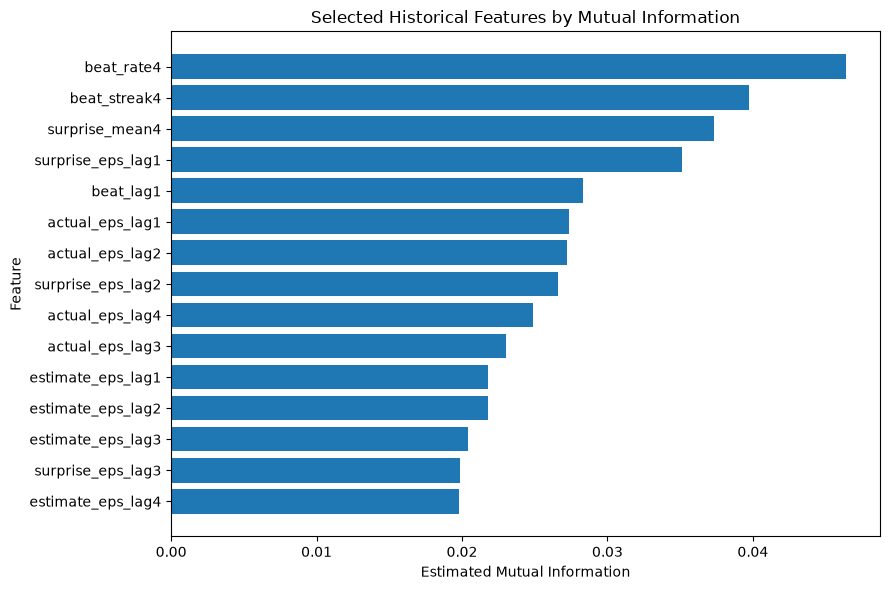

In [16]:

mi_results = pd.DataFrame({
    "Feature": transformed_columns,
    "Mutual Information": feature_selector.scores_,
    "Selected": feature_selector.get_support(),
})

mi_results = mi_results.sort_values(
    "Mutual Information",
    ascending=False,
).reset_index(drop=True)

print("Mutual-Information Feature Rankings")
display(mi_results)

selected_features = mi_results.loc[
    mi_results["Selected"]
]

print("\nSelected Features")
display(selected_features)

# visualizes selected columns
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = selected_features.sort_values(
    "Mutual Information"
)

ax.barh(
    plot_data["Feature"],
    plot_data["Mutual Information"],
)

ax.set_xlabel("Estimated Mutual Information")
ax.set_ylabel("Feature")
ax.set_title("Selected Historical Features by Mutual Information")

plt.tight_layout()
plt.show()

In [17]:
assert selected_training.shape[0] == len(training_features)
assert selected_validation.shape[0] == len(validation_features)

assert selected_training.shape[1] == MI_SELECTED_FEATURE_COUNT
assert selected_validation.shape[1] == MI_SELECTED_FEATURE_COUNT

assert np.isfinite(selected_training).all()
assert np.isfinite(selected_validation).all()

assert feature_selector.get_support().sum() == MI_SELECTED_FEATURE_COUNT

print("Mutual-information feature selection completed successfully.")

Mutual-information feature selection completed successfully.
